# Лабораторная работа №3

**Классические модели: Red Wine Quality**

ФИО: Шеранов Александр Сергеевич  
Группа: БИВТ-24-СП-4

Результаты получены реальным выполнением ячеек. RANDOM_STATE = 42.

## Задание преподавателя

  
- Обучить различного рода модели машинного обучения и сравнить их между собой  

---
## Читайте задание внимательно

Исходные данные:
1. В [табличке](https://docs.google.com/spreadsheets/d/1NOE0D4JQgD6LbvUqWboUI1TFj4P87ugbqUTDquxlGEI/edit?usp=sharing) необходимо узнать название своего датасета 
2. Скачать нужны вам данные можно в [Google Drive](https://drive.google.com/drive/folders/1sbsjBsJ_ln0XgXCI9R6s17pvyvApgcwF?usp=sharing)
  
---
Теперь по пунктам, что я от вас жду:  
1. Загрузить необходимые данные к себе и считать (read) их в переменную.
2. Понять, у вас задача классификации (бинарной или многоклассовой) или регрессии (**если у вас многоклассовая классификация, прочтите P.S.S. внизу**).
3. Сделать предобработку данных:  
     1. Разделить выборку на тренировочную (train) и тестовую (test). _Обратите внимание, что обучать скейлеры и определять, какими значениями вы будете заполнять пропуски, вы будете на train выборке, а применять и на train, и на test_.
     2. Проверить пропуски в данных. Если они есть, заполнить одной из стратегий, предложенных в ноутбуке для семинара №3. P.S. Для численных и категориальных переменных будут разные стратегии.
     3. Отнормировать численные переменные (`StandardScaler`, `MinMaxScaler`).
     4. Закодировать категориальные признаки по одной из стратегий.
4. Обучить на тренировочном множестве:
     1. Линейную модель (`LogisticRegression`, `LinearRegression`)
     2. Деревянную модель (`DecisionTreeClassifier`, `DecisionTreeRegressor`) (тут советую попробовать разные глубины деревьев)
     3. K-ближайших соседей (`KNeighborsClassifier`, `KNeighborsRegressor`) (тут тоже есть смысл попробовать разные `k`)
     4. Случайный лес (`RandomForestClassifier`, `RandomForestRegressor`) 
5. Посчитайте метрики на train и test множествах:
     1. Для задачи классификации -- Accuracy, ROC-AUC (график + значение), PR-кривую (график), F1-score
     2. Для задачи регрессии -- MAE, RMSE, MAPE
6. Сравните метрики относительно train/test, так и относительно разных моделей. Ответьте на следующие вопросы:
     1. Какая модель справилась лучше с поставленной задачей?
     2. Имеет ли место переобучение?
     3. Имеет ли место недообучение?
     4. Как можно улучшить метрики моделей?

---
P.S.  
Просьба -- делать каждое задание в отдельных ячейках и с отдельными заголовками (как пункт 1 и 2 в этом ноутбуке) типа  
- Заголовок
- Ячейки с кодом
- Другой заголовок
- Другие ячейки с кодом

P.S.S.  
Если вам повезло с многоклассовой классификацией, вам будет необходимо понять, умеет ли алгоритм работать с несколькими классами одновременно (обычно они не умеют). Поэтому вам может понадобиться такая штука, как OneVsRestClassifier ([ссылка](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html#sklearn.multiclass.OneVsRestClassifier)), но советую ознакомиться с этой [страницей](https://scikit-learn.org/stable/modules/multiclass.html), здесь представлена более полная информация.

## 1. Загрузка данных и постановка задачи

Источник: https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009 . Используется CSV преподавателя, сохранённый в `data/`. Вход — 11 физико-химических измерений; цель — `quality`. Рассматривается многоклассовая классификация шести наблюдаемых оценок 3–8. Цель порядковая, но в этой постановке точная оценка считается классом; соседняя и далёкая ошибки в Accuracy равнозначны. Поэтому можно дополнительно исследовать порядковые модели в будущей работе.

In [1]:
from pathlib import Path
import io, json, random
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

def show_plot(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    display(DisplayImage(data=buf.getvalue()))
    plt.close(fig)

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import joblib
raw = pd.read_csv(ROOT / "data/winequality-red.csv")
print("Исходный размер:", raw.shape)
display(raw.head())

Исходный размер: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Повторы, разбиение и предобработка

В EDA обнаружено 240 полных повторов. Перед моделированием оставляется одна копия каждой полной строки. Проверяется отсутствие противоречивых меток для одинаковых входов и пересечения входов между train/test. После удаления повторов применяется стратифицированное разбиение 80/20 с фиксированным seed. Оценки всех классов сохраняются.

Все входы численные: категориальных столбцов нет, дополнительное кодирование не нужно. Цель имеет метки 3–8, поддерживаемые sklearn непосредственно. `SimpleImputer(median)` и `StandardScaler` находятся внутри Pipeline: каждый CV-fold и окончательный train обучают их отдельно. Ни средние, ни медианы теста при обучении не используются. Для деревьев масштабирование не обязательно, но не меняет порядок значений.

In [2]:
feature_names = raw.columns.drop("quality").tolist()
conflicts = raw.groupby(feature_names)["quality"].nunique()
assert not (conflicts > 1).any(), "Нужна отдельная обработка противоречивых меток"
data = raw.drop_duplicates().reset_index(drop=True)
X, y = data[feature_names], data["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, stratify=y, random_state=SEED)
classes = np.sort(y.unique())
assert set(map(tuple, X_train.to_numpy())).isdisjoint(set(map(tuple, X_test.to_numpy())))
print("Удалено повторов:", len(raw)-len(data))
print("Размер train/test:", X_train.shape, X_test.shape)
print("Пропуски в train/test:", X_train.isna().sum().sum(), X_test.isna().sum().sum())
display(pd.concat([y_train.value_counts().sort_index().rename("train"),
                   y_test.value_counts().sort_index().rename("test")], axis=1))

Удалено повторов: 240
Размер train/test: (1087, 11) (272, 11)
Пропуски в train/test: 0 0


,train,test
quality,,
3,8,2
4,42,11
5,461,116
6,428,107
7,134,33
8,14,3


## 3. Обучение и выбор параметров

Для каждой семьи моделей проверяется несколько настроек. Используется 3-fold StratifiedKFold только внутри train. Критерий выбора — **macro-F1**, который даёт каждому классу равный вес при дисбалансе. Лучшая семья тоже выбирается по CV до просмотра test. Логистическая регрессия, дерево, KNN и случайный лес умеют работать с несколькими классами; OneVsRest-обёртка для их обучения здесь не требуется. В расчёте ROC применяется подход one-vs-rest.

Поиск ограничен приведённой сеткой. Test служит для финального сравнения, а не для повторного выбора гиперпараметров. DummyClassifier показывает результат предсказания одного наиболее частого класса.

In [3]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
specs = {
    "LogisticRegression": (LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
                           {"model__C": [.1, 1, 10]}),
    "DecisionTree": (DecisionTreeClassifier(random_state=SEED, class_weight="balanced"),
                     {"model__max_depth": [3, 6, None], "model__min_samples_leaf": [1, 3]}),
    "KNN": (KNeighborsClassifier(), {"model__n_neighbors": [3, 5, 9, 15]}),
    "RandomForest": (RandomForestClassifier(n_estimators=200, random_state=SEED,
                                            class_weight="balanced_subsample", n_jobs=1),
                     {"model__max_depth": [6, None], "model__min_samples_leaf": [1, 2]})
}
models, cv_rows = {}, []
for name, (estimator, params) in specs.items():
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()), ("model", estimator)])
    search = GridSearchCV(pipe, params, cv=cv, scoring="f1_macro", n_jobs=2, refit=True)
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    cv_rows.append({"model": name, "cv_macro_f1": search.best_score_,
                    "best_params": json.dumps(search.best_params_)})
cv_results = pd.DataFrame(cv_rows).sort_values("cv_macro_f1", ascending=False)
selected_name = cv_results.iloc[0]["model"]
print("Выбранная по CV модель:", selected_name)
display(cv_results)
models["Dummy_most_frequent"] = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
cv_results.to_csv(ARTIFACTS / "lab3_cv.csv", index=False)

Выбранная по CV модель: RandomForest


,model,cv_macro_f1,best_params
3,RandomForest,0.324055,"{""model__max_depth"": 6, ""model__min_samples_le..."
0,LogisticRegression,0.299951,"{""model__C"": 10}"
1,DecisionTree,0.287266,"{""model__max_depth"": null, ""model__min_samples..."
2,KNN,0.269842,"{""model__n_neighbors"": 3}"


## 4. Метрики на train и test

Accuracy — доля точных предсказаний. Macro-F1 — среднее F1 по классам. ROC-AUC macro OVR — среднее AUC шести задач «данная оценка против остальных». Average Precision macro дополняет PR-кривые. Вероятности берутся из `predict_proba`, а не из жёстких предсказаний. Метрики train здесь считаются на тех же данных, на которых модель обучалась, поэтому они оптимистичны.

In [4]:
rows = []
for name, model in models.items():
    for split, xpart, ypart in [("train", X_train, y_train), ("test", X_test, y_test)]:
        prediction = model.predict(xpart)
        probability = model.predict_proba(xpart)
        assert np.array_equal(model.classes_, classes)
        binary = label_binarize(ypart, classes=classes)
        rows.append({"model": name, "split": split,
                     "accuracy": accuracy_score(ypart, prediction),
                     "macro_f1": f1_score(ypart, prediction, average="macro", zero_division=0),
                     "roc_auc_macro_ovr": roc_auc_score(ypart, probability, multi_class="ovr", average="macro"),
                     "average_precision_macro": average_precision_score(binary, probability, average="macro")})
metrics = pd.DataFrame(rows)
display(metrics.round(4))
metrics.to_csv(ARTIFACTS / "lab3_metrics.csv", index=False)

,model,split,accuracy,macro_f1,roc_auc_macro_ovr,average_precision_macro
0,LogisticRegression,train,0.4581,0.3564,0.8402,0.3916
1,LogisticRegression,test,0.4081,0.2435,0.6919,0.3023
2,DecisionTree,train,1.0000,1.0000,1.0000,1.0000
3,DecisionTree,test,0.5037,0.2863,0.5848,0.2182
4,KNN,train,0.7415,0.5711,0.9514,0.6326
5,KNN,test,0.5221,0.2869,0.6295,0.2551
6,RandomForest,train,0.7222,0.8108,0.9548,0.9083
7,RandomForest,test,0.5478,0.3106,0.7755,0.3502
8,Dummy_most_frequent,train,0.4241,0.0993,0.5000,0.1667
9,Dummy_most_frequent,test,0.4265,0.0997,0.5000,0.1667


## 5. ROC- и PR-кривые всех моделей на train/test

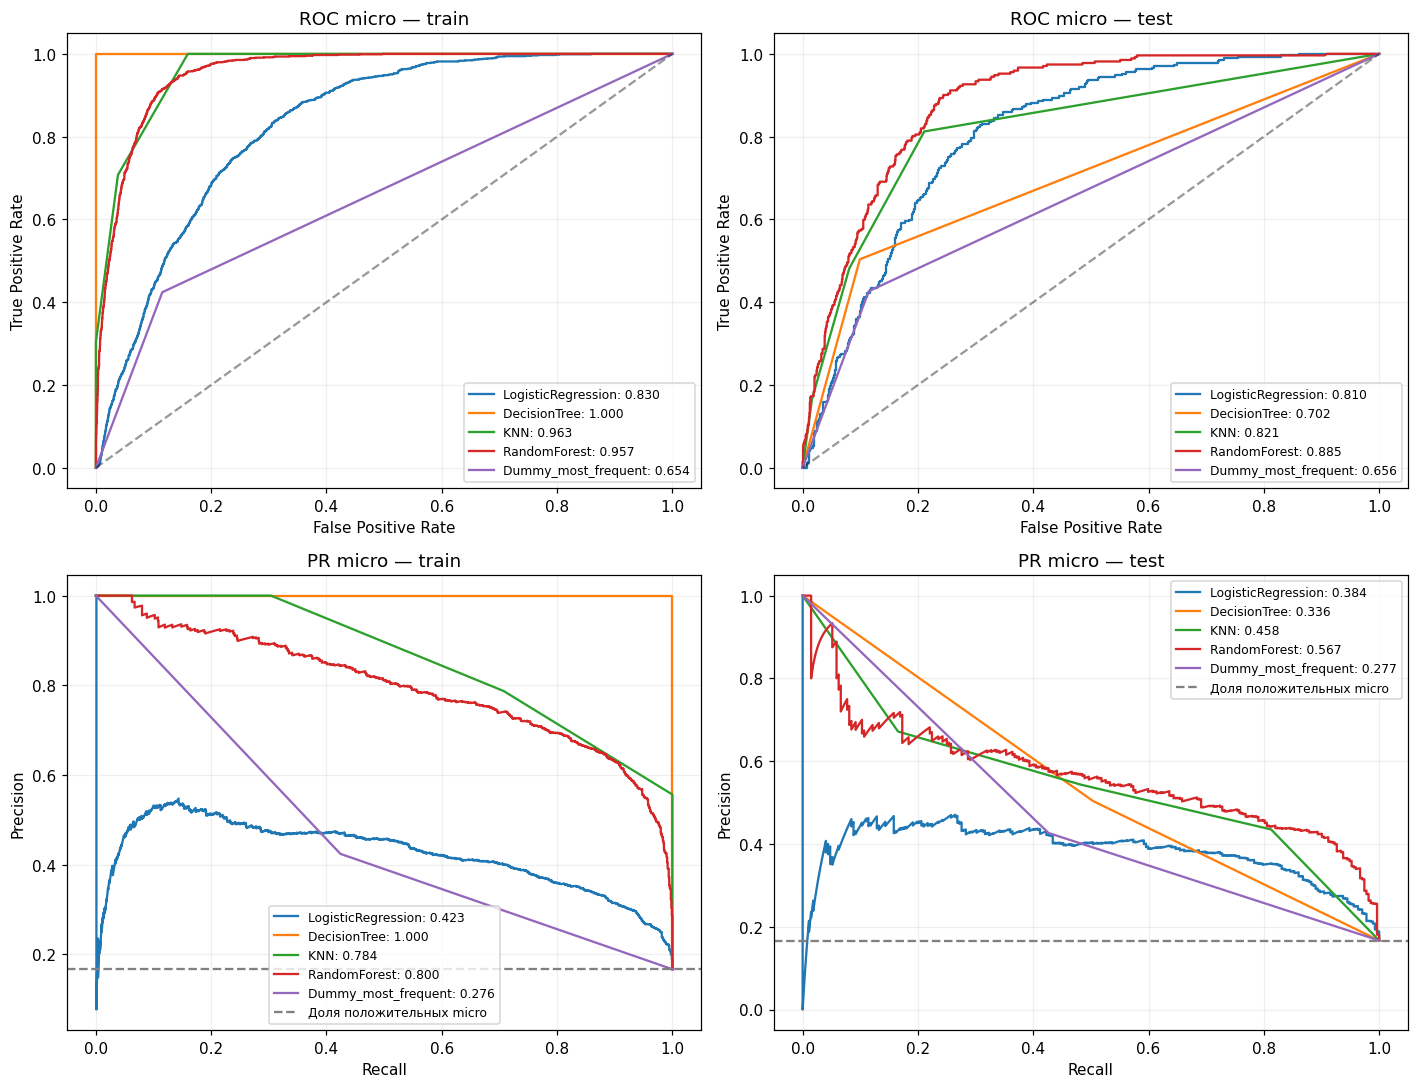

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for col, (split, xpart, ypart) in enumerate([("train", X_train, y_train), ("test", X_test, y_test)]):
    binary = label_binarize(ypart, classes=classes)
    for name, model in models.items():
        probability = model.predict_proba(xpart)
        fpr, tpr, _ = roc_curve(binary.ravel(), probability.ravel())
        precision, recall, _ = precision_recall_curve(binary.ravel(), probability.ravel())
        auc_micro = roc_auc_score(binary, probability, average="micro")
        ap_micro = average_precision_score(binary, probability, average="micro")
        axes[0, col].plot(fpr, tpr, label=f"{name}: {auc_micro:.3f}")
        axes[1, col].plot(recall, precision, label=f"{name}: {ap_micro:.3f}")
    axes[0, col].plot([0, 1], [0, 1], "k--", alpha=.4)
    axes[1, col].axhline(binary.mean(), ls="--", color="grey", label="Доля положительных micro")
    axes[0, col].set(title=f"ROC micro — {split}", xlabel="False Positive Rate", ylabel="True Positive Rate")
    axes[1, col].set(title=f"PR micro — {split}", xlabel="Recall", ylabel="Precision")
    for ax in axes[:, col]: ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.tight_layout()
show_plot(fig)

Micro объединяет все one-vs-rest решения, поэтому сильнее отражает частые классы. Для редких оценок ниже показаны отдельные кривые выбранной по CV модели. На PR-графике площадь характеризуется Average Precision, а не обычным трапецеидальным ROC-AUC.

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.30      0.27      0.29        11
           5       0.64      0.77      0.70       116
           6       0.61      0.32      0.42       107
           7       0.34      0.70      0.46        33
           8       0.00      0.00      0.00         3

    accuracy                           0.55       272
   macro avg       0.32      0.34      0.31       272
weighted avg       0.57      0.55      0.53       272

Out[6]: ['/workspace/scratch/895c4588cf83/submission/artifacts/lab3_selected_model.joblib']


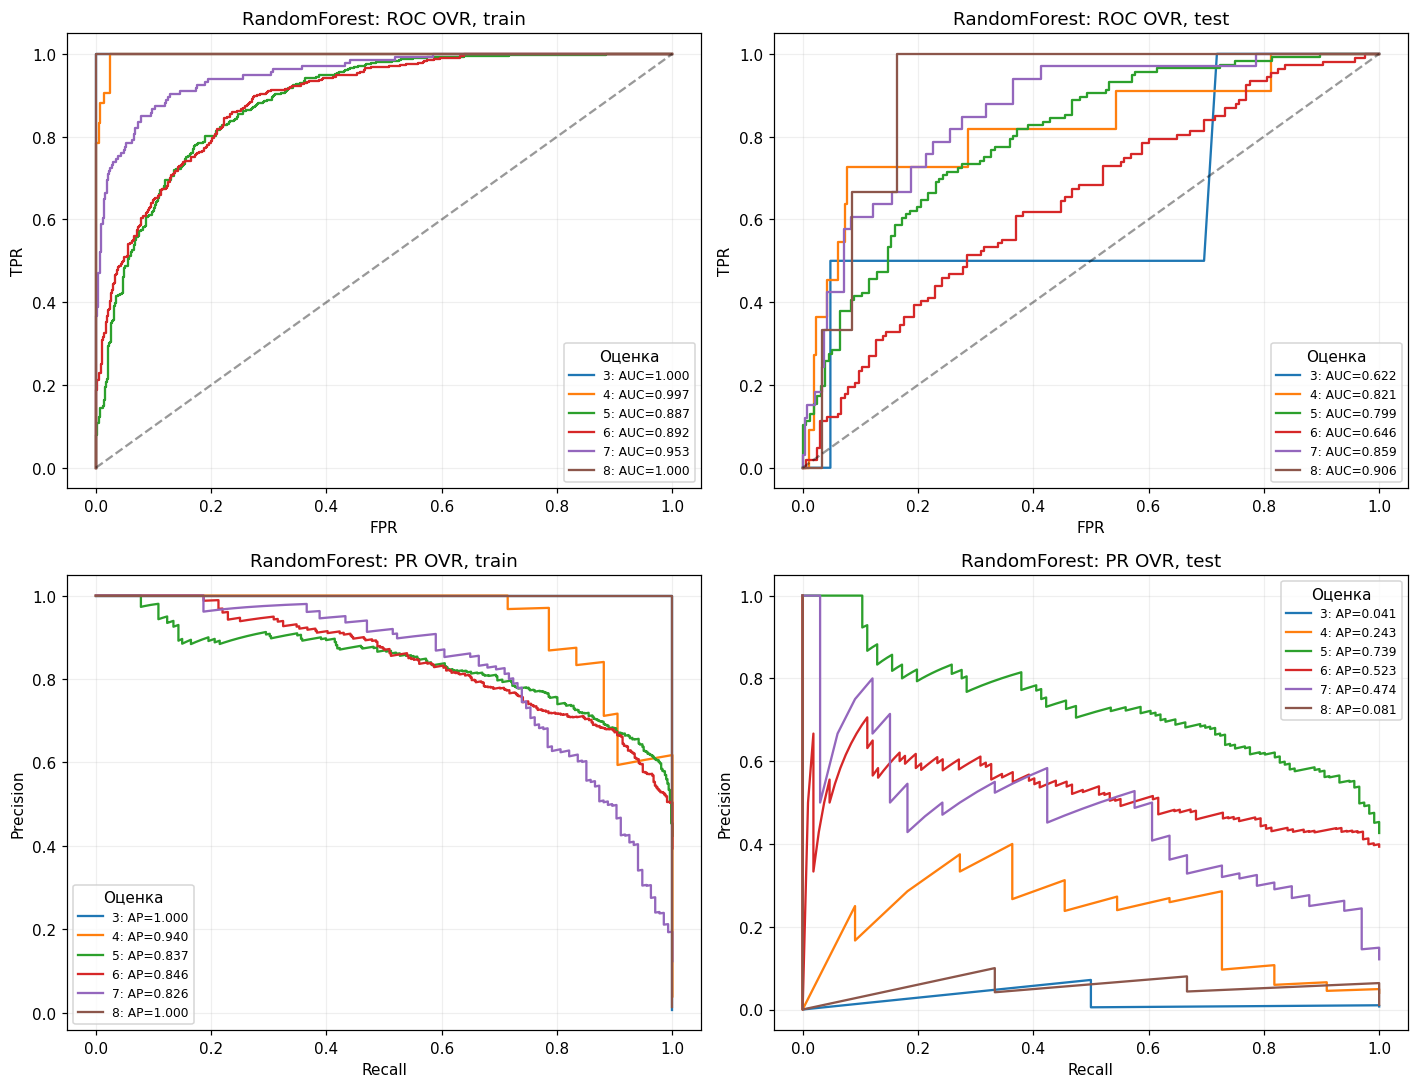

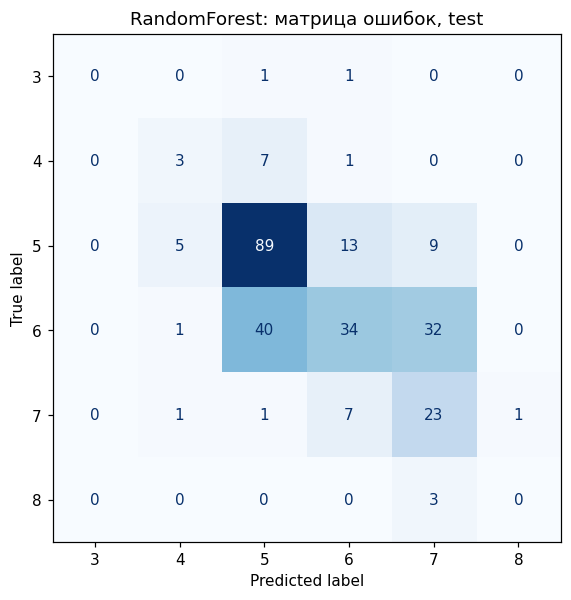

In [6]:
selected = models[selected_name]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for col, (split, xpart, ypart) in enumerate([("train", X_train, y_train), ("test", X_test, y_test)]):
    binary = label_binarize(ypart, classes=classes)
    probability = selected.predict_proba(xpart)
    for j, label in enumerate(classes):
        fpr, tpr, _ = roc_curve(binary[:, j], probability[:, j])
        precision, recall, _ = precision_recall_curve(binary[:, j], probability[:, j])
        axes[0, col].plot(fpr, tpr, label=f"{label}: AUC={roc_auc_score(binary[:, j], probability[:, j]):.3f}")
        axes[1, col].plot(recall, precision, label=f"{label}: AP={average_precision_score(binary[:, j], probability[:, j]):.3f}")
    axes[0, col].plot([0, 1], [0, 1], "k--", alpha=.4)
    axes[0, col].set(title=f"{selected_name}: ROC OVR, {split}", xlabel="FPR", ylabel="TPR")
    axes[1, col].set(title=f"{selected_name}: PR OVR, {split}", xlabel="Recall", ylabel="Precision")
    for ax in axes[:, col]: ax.legend(title="Оценка", fontsize=8); ax.grid(alpha=.2)
fig.tight_layout(); show_plot(fig)
print(classification_report(y_test, selected.predict(X_test), labels=classes, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, selected.predict(X_test), labels=classes, ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{selected_name}: матрица ошибок, test")
show_plot(fig)
joblib.dump(selected, ARTIFACTS / "lab3_selected_model.joblib")

## 6. Сравнение и выводы

In [7]:
train_table = metrics.query("split == 'train'").set_index("model")
test_table = metrics.query("split == 'test'").set_index("model")
comparison = pd.DataFrame({"train_accuracy": train_table.accuracy, "test_accuracy": test_table.accuracy,
                           "train_macro_f1": train_table.macro_f1, "test_macro_f1": test_table.macro_f1})
comparison["f1_gap"] = comparison.train_macro_f1 - comparison.test_macro_f1
display(comparison.round(4))
print(f"Выбор до просмотра теста по CV macro-F1: {selected_name}.")
print(f"Лидер по наблюдаемому test macro-F1: {test_table.macro_f1.idxmax()} (описательное сравнение, без повторной настройки).")
for name in specs:
    gap = comparison.loc[name, "f1_gap"]
    print(f"{name}: разрыв train−test macro-F1 = {gap:.3f}.")

Выбор до просмотра теста по CV macro-F1: RandomForest.
Лидер по наблюдаемому test macro-F1: RandomForest (описательное сравнение, без повторной настройки).
LogisticRegression: разрыв train−test macro-F1 = 0.113.
DecisionTree: разрыв train−test macro-F1 = 0.714.
KNN: разрыв train−test macro-F1 = 0.284.
RandomForest: разрыв train−test macro-F1 = 0.500.


,train_accuracy,test_accuracy,train_macro_f1,test_macro_f1,f1_gap
model,,,,,
LogisticRegression,0.4581,0.4081,0.3564,0.2435,0.1129
DecisionTree,1.0000,0.5037,1.0000,0.2863,0.7137
KNN,0.7415,0.5221,0.5711,0.2869,0.2841
RandomForest,0.7222,0.5478,0.8108,0.3106,0.5002
Dummy_most_frequent,0.4241,0.4265,0.0993,0.0997,-0.0004


**Интерпретация.** Большой положительный разрыв train/test у гибкой модели — признак переобучения. Низкие train и test одновременно могут указывать на недостаточную выразительность или неподходящие признаки; по одному разрыву нельзя доказать недообучение. Сопоставление с Dummy и CV помогает отделить это от дисбаланса. Редкие классы представлены единицами объектов в тесте, поэтому их AUC/F1 нестабильны.

Улучшения: ограничить глубину деревьев, увеличить размер листа, подбирать регуляризацию и k только на train-CV, расширить число независимых измерений редких оценок, исследовать порядковую постановку. Один split не даёт доверительного интервала качества. Масштабирование и заполнение пропусков выполнены без утечки; все числа и графики выше получены запуском кода.

## Фактические результаты и ответы на вопросы

По трёхкратной кросс-валидации выбран RandomForest (macro-F1 ≈ 0,324). На отложенном test он получил Accuracy ≈ 0,548, macro-F1 ≈ 0,311 и macro ROC-AUC ≈ 0,776; Dummy — Accuracy ≈ 0,426 и macro-F1 ≈ 0,100. Поэтому лес полезнее константного ответа, но результат по редким оценкам остаётся слабым.

Неограниченное дерево получило train Accuracy=1,000 и test≈0,504: это явный признак переобучения. У леса тоже большой разрыв macro-F1 train/test (≈0,811 против ≈0,311). Линейная модель получила ≈0,408 test Accuracy; балансировка классов и линейные границы в этой конфигурации не дали сильного результата. Это не доказывает, что вся семья линейных моделей непригодна.

В матрице ошибок выбранного леса нет верных ответов для оценок 3 и 8. Для этих классов в тесте всего 2 и 3 образца; выводы о них очень неустойчивы. Основные ошибки — смешение соседних оценок. Улучшать нужно баланс и устойчивость, а не только общую Accuracy. После просмотра test повторная настройка не проводилась.